In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [25]:
df = pd.read_csv("dataset/uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [27]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [28]:
df.dropna(inplace=True)

In [29]:
df.drop(['Unnamed: 0','key'], axis=1, inplace=True)

In [30]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df.drop('pickup_datetime', axis=1, inplace=True)

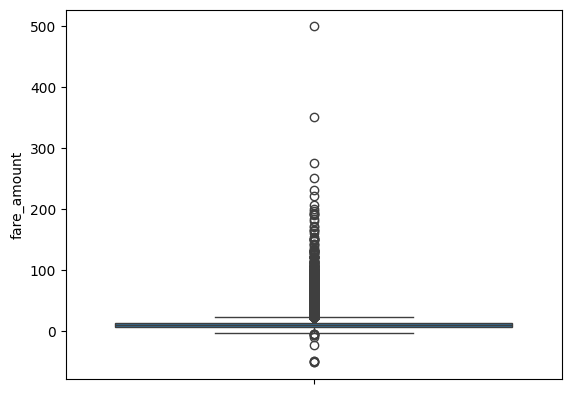

In [31]:
sns.boxplot(df['fare_amount'])
plt.show()

In [32]:
df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'] >= 1) &
    (df['passenger_count'] <= 6)
]

In [33]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3- Q1
lower = Q1- 1.5*IQR
upper = Q3 + 1.5*IQR
df = df[(df['fare_amount'] >= lower) &
(df['fare_amount'] <= upper)]

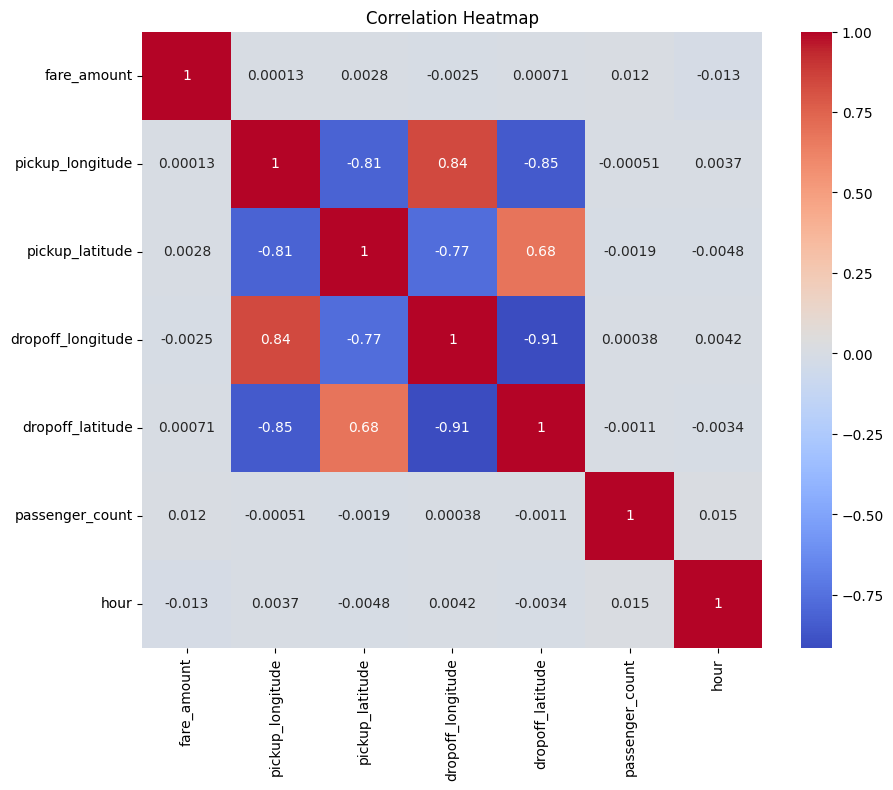

In [34]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [35]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']
print(X.shape, y.shape)

(182147, 6) (182147,)


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.2,
random_state=42
)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(145717, 6) (145717,) (36430, 6) (36430,)


In [37]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

In [38]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [39]:
print("Linear Regression")
print("RMSE:",
np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2 Score:",
r2_score(y_test, lr_pred))
print("Random Forest")
print("RMSE:",
np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:",
r2_score(y_test, rf_pred))

Linear Regression
RMSE: 4.132135362825812
R2 Score: 0.00022637430325767038
Random Forest
RMSE: 2.1792657563457807
R2 Score: 0.7219179315326727


In [40]:
comparison = pd.DataFrame({
"Model":["Linear Regression","Random Forest"],
"RMSE":[
np.sqrt(mean_squared_error(y_test, lr_pred)),
np.sqrt(mean_squared_error(y_test, rf_pred))
],
"R2 Score":[
r2_score(y_test, lr_pred),
r2_score(y_test, rf_pred)
]
})
comparison

,Model,RMSE,R2 Score
0,Linear Regression,4.132135,0.000226
1,Random Forest,2.179266,0.721918
